Goals:
1. Ingest a real eeg recording from open source dataset with messy signal and plot it
2. Preprocess as per documentation and prior examples
3. Overlay preprocessed signal on top of raw messy signal


In [1]:
#install required libraries
%pip install mne
import mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 19.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 33.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 30.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 13.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 27.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 29.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20/20 [mne]32m19/20 [mne]lotlib]malizer]
Note: you may need to restart the kernel to use updated packages.


# Ingest eeg recording and plot it
I used mne given sample eeg dataset "EEGBCI" for the sake of getting familiar with pipeline
Switch out for more representative dataset later.

About the dataset: 
1. These are original, un-filtered recordings
2. 64-channel EEG recordings from 109 subjects doing motor imagery tasks
3. 14 runs on each subject in EDF+ format
4. 10-10 electrode placement, sampling rate of 160 Hz
https://physionet.org/content/eegmmidb/1.0.0/ 

In [ ]:
from mne.io import concatenate_raws, read_raw_edf
from mne.datasets import eegbci

#just rand subject and runs for now
subjects = 1
runs = [1 , 2]

custom_path = "./eeg_data/" #keep it in the same dir
mne.set_config('MNE_DATASETS_EEGBCI_PATH', custom_path)
raw_fnames = list()

try: 
    raw_fnames = eegbci.load_data(subjects, runs, path=custom_path) #list of paths
    print(f"raw_fnames: {raw_fnames}")
except Exception as e:
    print(f"Error loading data: {e}")

raws = [read_raw_edf(fname, preload=True) for fname in raw_fnames]
for raw in raws:
    eegbci.standardize(raw)

## whats written in the edfs?
first_fname = raw_fnames[0] #path to first
print(f"first_fname: {first_fname}")
output_txt_path = "./eeg_data/metadata.txt" #path to output txt file

with open(first_fname, "rb") as edf:
    header_bytes = edf.read(256)  # Read the first 256 bytes of the file (ascii header is std for edf)

metadata_text = header_bytes.decode("ascii", errors="ignore")

with open(output_txt_path, "w") as txt_file:
    txt_file.write(metadata_text)
    print(f"Metadata written")



raw_fnames: [PosixPath('eeg_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R01.edf'), PosixPath('eeg_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R02.edf')]
Extracting EDF parameters from eeg_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R01.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 9759  =      0.000 ...    60.994 secs...
Extracting EDF parameters from eeg_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R02.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 9759  =      0.000 ...    60.994 secs...
first_fname: eeg_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R01.edf
Metadata written


# so now i have data to play with, let's plot something

amount of time points in raw: 9760
recording duration in seconds: 61.0


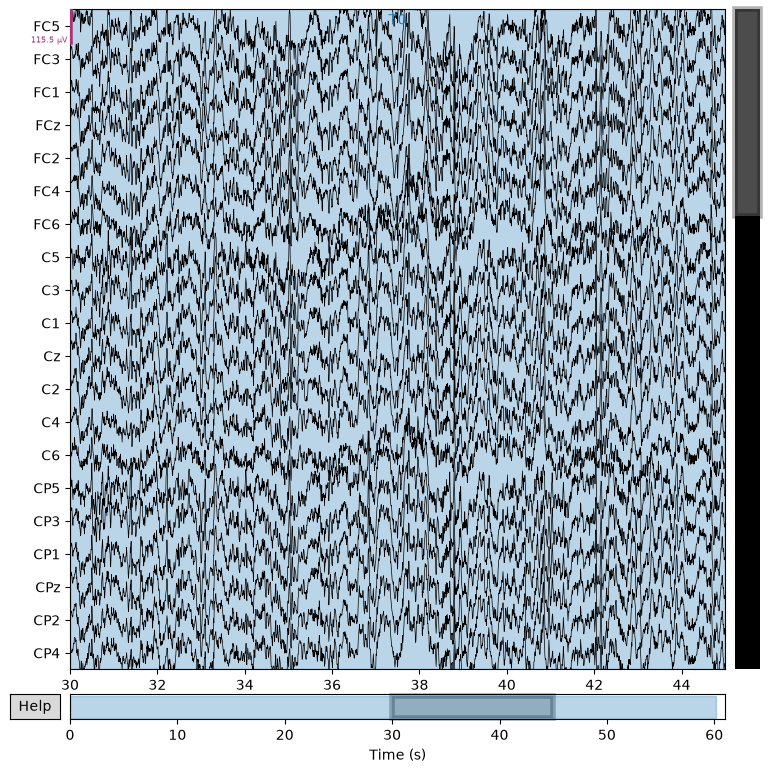

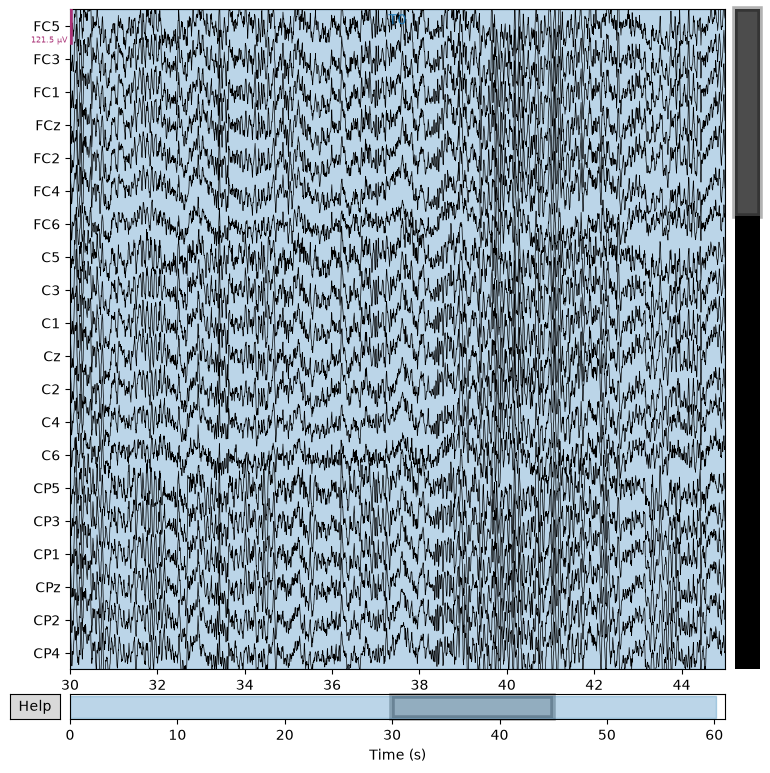

In [19]:
#we already loaded and read the raw edf above in raws
#so just plot each edf in the raws list
# note theres 64 channels, im just checking out the first few.

for raw in raws:
    if raw == raws[0]:
        print(f"amount of time points in raw: {len(raw)}")
        recording_duration = len(raw)/ raw.info['sfreq'] #time points/sampling frequency
        print(f"recording duration in seconds: {recording_duration}")
    raw.plot(start=30, duration=15, n_channels=20, scalings='auto', title='EEG Data', show=True, block=True)

some notes:
this is mne native plot function 
it also supports picking start and end by doing raw.copy().crop.plot
so you can plot a specific time window
you can also raw.plot(start=15, duration=10) for example if you want to start at 15s mark and go for 10 seconds

also 'auto' scaling allows joint scaling (every channel of same type (eeg for ex) will take the same scaling factor) - here it's in the hundreds microvolt range. should make sure theres no outliers completely tanking this scaling factor.

questions:
1. why do all signals look so similar on each channel? im not seeing alot of noise or bad channels or anything which is good i guess but it feels weird no (??) 

# spectral features?

Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).


/var/folders/rf/qdpvz44j52517w6nmdfb44gw0000gn/T/ipykernel_11459/3272953377.py:4: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  psd.plot()
/Users/nicoleyu/opt/anaconda3/envs/eeg/lib/python3.13/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


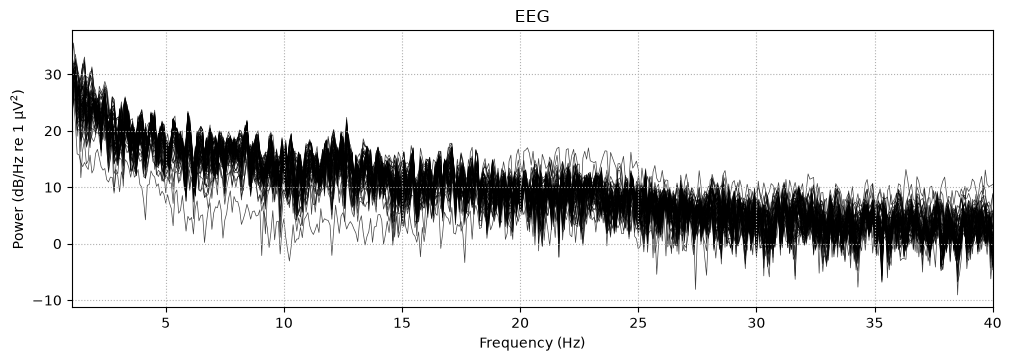

In [ ]:
psd = raws[0].compute_psd(fmin=1, fmax=40)
psd.plot()

# nice okay lets see if we can do some preprocessing on this signal

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 529 samples (3.306 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 59 - 61 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 59.35
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 59.10 Hz)
- Upper passband edge

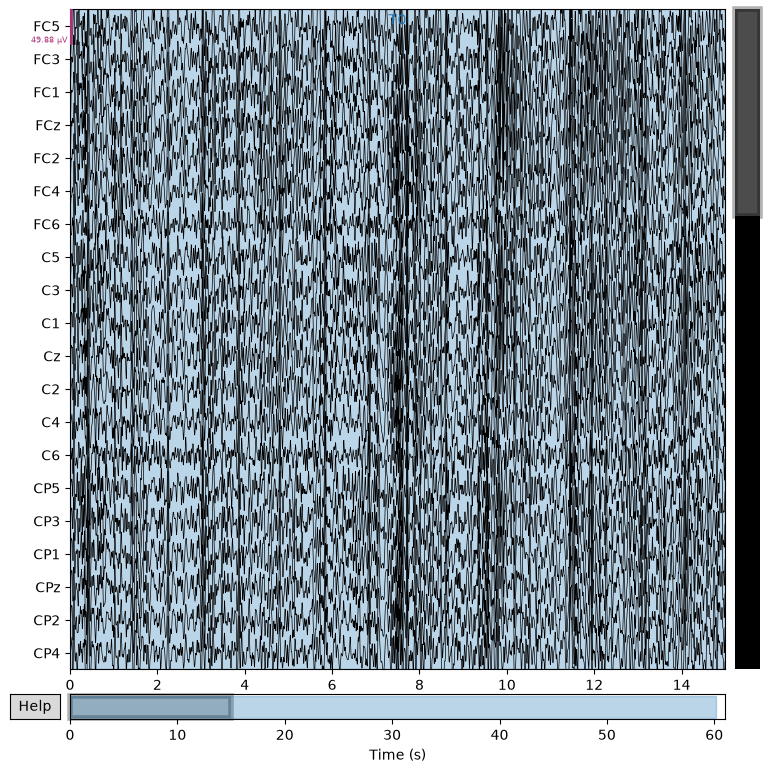

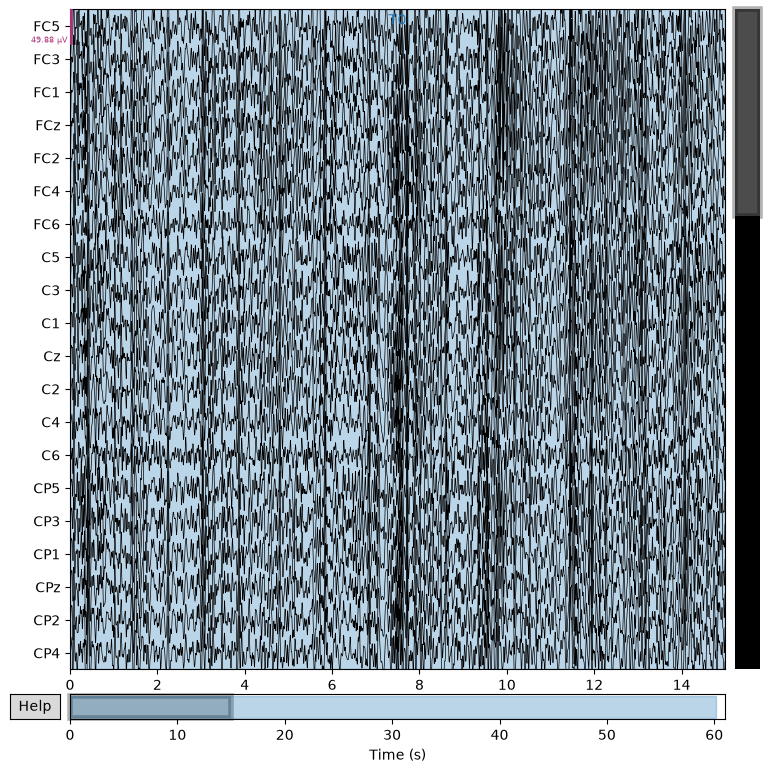

In [25]:
s1r1_raw = raws[0] #subject 1, run 1

s1r1_raw.filter(l_freq=1.0, h_freq=40.0)
s1r1_raw.notch_filter(freqs=60.0) #remove 60Hz line noise

s1r1_raw.plot(duration=15, n_channels=20, scalings='auto', title='EEG Data (Filtered)', show=True, block=True)